In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Mateix directori arrel que als teus notebooks
ROOT_DIR = Path.cwd().resolve().parents[1]
carpeta_dades = ROOT_DIR / "data" / "processed" / "education"

ruta_global = carpeta_dades / "resultats_academics__quart_eso_processat.csv"
ruta_pub100k = carpeta_dades / "resultats_academics_quart_eso_processat_nou.csv"

cols_notes = ["PCAT", "PCAT_CL", "PCAT_EE", "PMAT"]

# ---------------------------------------------------------
# 1. Processament de l'arxiu GLOBAL (tots els centres)
# ---------------------------------------------------------
df_global = pd.read_csv(ruta_global, sep=";", decimal=",")

df_global["GENERE"] = df_global["GENERE"].astype(str).str.strip().str.upper()
df_global = df_global[df_global["GENERE"].isin(["H", "D"])].copy()

df_global["ANY"] = pd.to_numeric(df_global["ANY"], errors="coerce")
for col in cols_notes:
    df_global[col] = pd.to_numeric(
        df_global[col].astype(str).str.replace(",", ".", regex=False),
        errors="coerce"
    )

df_global_net = (
    df_global
    .dropna(subset=["ANY"])
    .dropna(subset=cols_notes, how="all")
    .copy()
)
df_global_net["ANY"] = df_global_net["ANY"].astype(int)

mitjanes_global = (
    df_global_net
    .groupby("ANY")[cols_notes]
    .mean()
    .sort_index()
)

# ---------------------------------------------------------
# 2. Processament de l'arxiu PÚBLIQUES (<= 100k habitants)
# ---------------------------------------------------------
df_pub = pd.read_csv(ruta_pub100k, sep=";", encoding="utf-8", encoding_errors="replace")
if df_pub.shape[1] == 1:
    df_pub = pd.read_csv(ruta_pub100k, sep=",", encoding="utf-8", encoding_errors="replace")

df_pub_net = pd.DataFrame({
    "ANY": pd.to_numeric(df_pub.iloc[:, 0], errors="coerce"),
    "PCAT": pd.to_numeric(df_pub.iloc[:, 1].astype(str).str.replace(",", ".", regex=False), errors="coerce"),
    "PCAT_CL": pd.to_numeric(df_pub.iloc[:, 2].astype(str).str.replace(",", ".", regex=False), errors="coerce"),
    "PCAT_EE": pd.to_numeric(df_pub.iloc[:, 3].astype(str).str.replace(",", ".", regex=False), errors="coerce"),
    "PMAT": pd.to_numeric(df_pub.iloc[:, 4].astype(str).str.replace(",", ".", regex=False), errors="coerce"),
    "NATURALESA": df_pub.iloc[:, 5].astype(str).str.strip(),
    "HABITAT": df_pub.iloc[:, 7].astype(str).str.strip()
})

cond_publica = (
    (~df_pub_net["NATURALESA"].str.contains("privada", case=False, na=False))
    & (df_pub_net["NATURALESA"] != "")
    & (df_pub_net["NATURALESA"].str.lower() != "nan")
)
cond_habitat = df_pub_net["HABITAT"].isin(["Fins a 10000", "De 10001 a 100000"])

df_pub_filtrat = (
    df_pub_net[cond_publica & cond_habitat]
    .dropna(subset=["ANY"])
    .dropna(subset=cols_notes, how="all")
    .copy()
)
df_pub_filtrat["ANY"] = df_pub_filtrat["ANY"].astype(int)

mitjanes_pub100k = (
    df_pub_filtrat
    .groupby("ANY")[cols_notes]
    .mean()
    .sort_index()
)

print(f"Alumnes vàlids (Global): {len(df_global_net)}")
print(f"Alumnes vàlids (Públiques ≤ 100k): {len(df_pub_filtrat)}")

C:\Users\carle\AppData\Local\Temp\ipykernel_10232\456243777.py:48: DtypeWarning: Columns (2: PCAT_CL) have mixed types. Specify dtype option on import or set low_memory=False.
  df_pub = pd.read_csv(ruta_pub100k, sep=";", encoding="utf-8", encoding_errors="replace")


Alumnes vàlids (Global): 914591
Alumnes vàlids (Públiques ≤ 100k): 409549


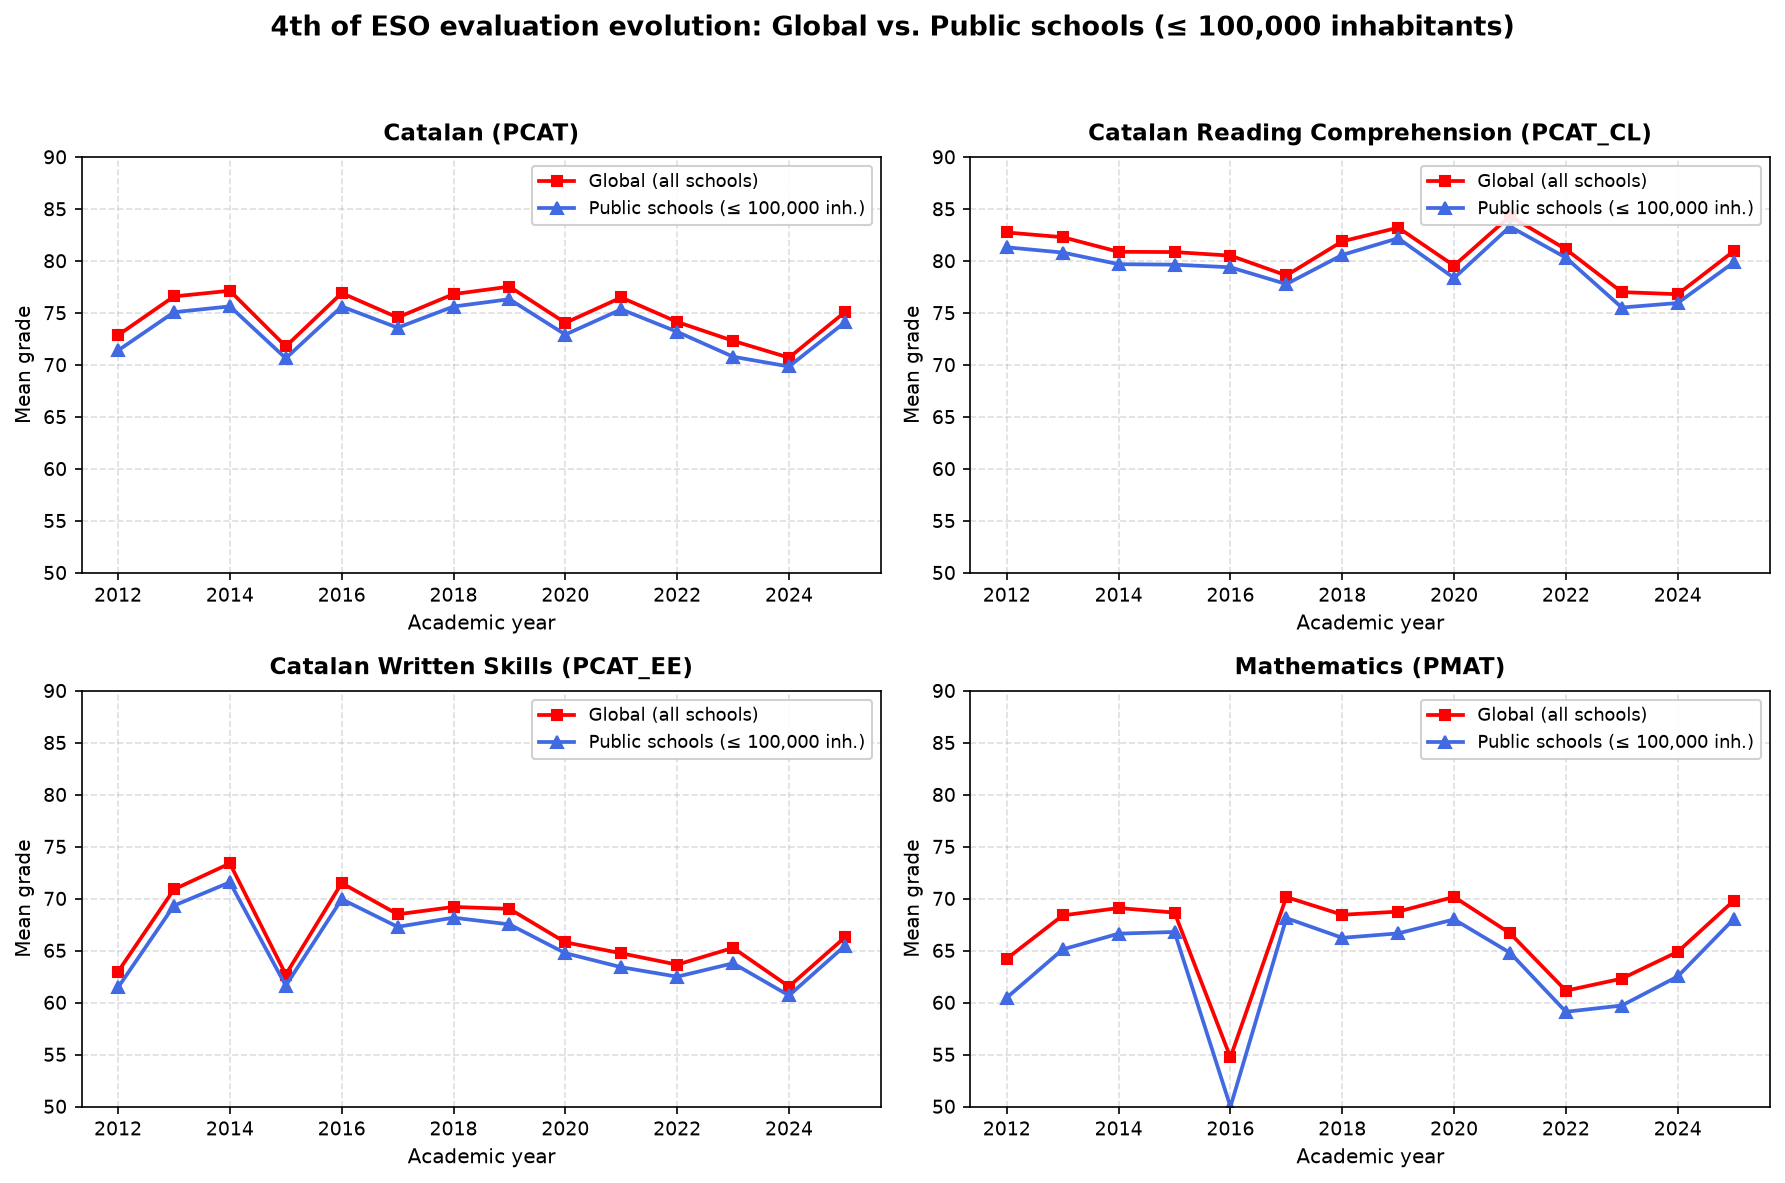

In [2]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), dpi=150)

competencies = [
    ("PCAT", "Catalan (PCAT)", axes[0, 0]),
    ("PCAT_CL", "Catalan Reading Comprehension (PCAT_CL)", axes[0, 1]),
    ("PCAT_EE", "Catalan Written Skills (PCAT_EE)", axes[1, 0]),
    ("PMAT", "Mathematics (PMAT)", axes[1, 1])
]

for col, titol, ax in competencies:
    # 1. Global: quadradets vermells
    ax.plot(
        mitjanes_global.index,
        mitjanes_global[col],
        color="red",
        marker="s",
        markersize=5,
        linewidth=1.8,
        label="Global (all schools)"
    )
    
    # 2. Públiques <= 100.000 habitants: trianglets blaus
    ax.plot(
        mitjanes_pub100k.index,
        mitjanes_pub100k[col],
        color="royalblue",
        marker="^",
        markersize=6,
        linewidth=1.8,
        label="Public schools (≤ 100,000 inh.)"
    )
    
    ax.set_title(titol, fontsize=11, fontweight="bold", pad=8)
    ax.set_xlabel("Academic year", fontsize=9.5)
    ax.set_ylabel("Mean grade", fontsize=9.5)
    ax.set_ylim(50, 90)
    ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
    ax.grid(True, linestyle="--", alpha=0.4)
    ax.tick_params(axis="both", labelsize=9)
    ax.legend(loc="upper right", frameon=True, facecolor="white", framealpha=0.9, fontsize=8.5)

fig.suptitle(
    "4th of ESO evaluation evolution: Global vs. Public schools (≤ 100,000 inhabitants)",
    fontsize=13,
    fontweight="bold",
    y=0.98
)

plt.tight_layout(rect=[0, 0, 1, 0.95])

# Desem la figura comparativa a la carpeta de resultats
ruta_figura = ROOT_DIR / "results" / "figures" / "evolucio_4t_eso_comparativa.png"
ruta_figura.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(ruta_figura, dpi=300, bbox_inches="tight")

plt.show()

 Year  Immigration  Emigration  Net_Migration
 2005      1573750      232720        1341030
 2006      1803210      474410        1328800
 2007      1956630      625180        1331450
 2008      1707250      753600         953650
 2009      1200120     1053850         146270
 2010      1187560     1071600         115960
 2011      1116900      913960         202940
 2012       868230      879850         -11620
 2013       797360      934720        -137360
 2014       915110      927820         -12710
 2015      1033910      751380         282530
 2016      1155920      658730         497190
 2017      1361430      783560         577870
 2018      1617130      644840         972290
 2019      1876450      737640        1138810
 2020      1090100      523080         567020
 2021      1673000      978780         694220
 2022      2468690      818000        1650690
 2023      2407530     1111620        1295910
 2024      2460160     1130730        1329430


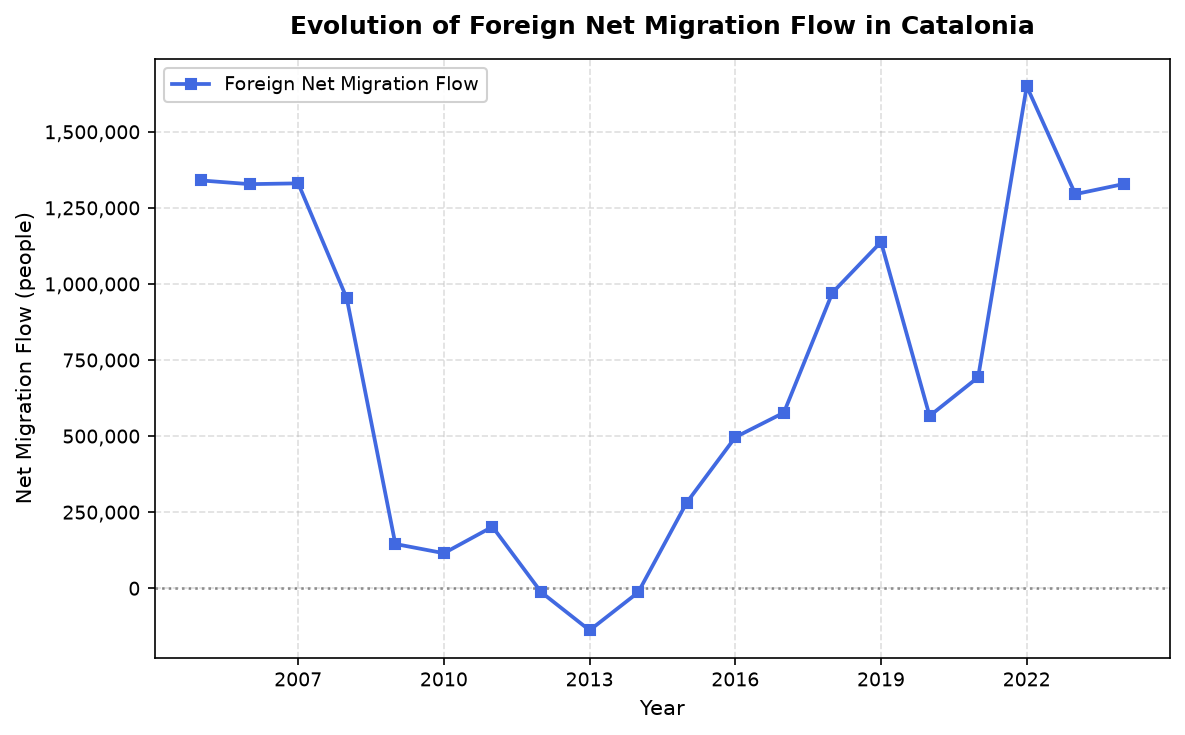

In [3]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import pandas as pd

# Mateix directori arrel que als teus notebooks
if "ROOT_DIR" not in globals():
    cwd = Path.cwd().resolve()
    ROOT_DIR = (
        cwd.parents[1]
        if (cwd.parents[1] / "data").exists()
        else (cwd.parents[0] if (cwd.parents[0] / "data").exists() else cwd)
    )

carpeta_migracio = ROOT_DIR / "data" / "processed" / "migration"
ruta_immigracions = carpeta_migracio / "immigracions_externes.csv"
ruta_emigracions = carpeta_migracio / "emigracions_externes.csv"


def processar_migracio_estrangera(ruta_csv: Path, nom_columna: str) -> pd.DataFrame:
    df = pd.read_csv(
        ruta_csv,
        sep=None,
        engine="python",
        encoding="utf-8",
        encoding_errors="replace"
    )

    any_col = pd.to_numeric(df.iloc[:, 0], errors="coerce")
    lloc_col = df.iloc[:, 1].astype(str).str.strip()
    nac_col = df.iloc[:, 2].astype(str).str.strip()
    sexe_col = df.iloc[:, 3].astype(str).str.strip()
    val_col = pd.to_numeric(
        df.iloc[:, -1].astype(str).str.strip().str.replace(".", "", regex=False),
        errors="coerce"
    )

    # Filtrem només nacionalitat "Estrangera" i evitem sumar files agregades "Total"
    cond_nac = nac_col.str.lower() == "estrangera"
    cond_lloc = lloc_col.str.lower() != "total"
    if (sexe_col.str.lower() == "total").any():
        cond_sexe = sexe_col.str.lower() == "total"
    else:
        cond_sexe = sexe_col.str.lower().isin(["homes", "dones"])

    df_net = pd.DataFrame({
        "Year": any_col,
        nom_columna: val_col
    })[cond_nac & cond_lloc & cond_sexe].dropna()

    df_net["Year"] = df_net["Year"].astype(int)
    return df_net.groupby("Year", as_index=False)[nom_columna].sum()


# 1. Càlcul d'entrades, sortides i flux migratori net (Entrant - Sortint)
df_in = processar_migracio_estrangera(ruta_immigracions, "Immigration")
df_out = processar_migracio_estrangera(ruta_emigracions, "Emigration")

df_flux = pd.merge(df_in, df_out, on="Year", how="inner").sort_values("Year")
df_flux["Net_Migration"] = df_flux["Immigration"] - df_flux["Emigration"]

print(df_flux.to_string(index=False))

# 2. Plot (timeline): Net Migration Flow vs. Year
fig, ax = plt.subplots(figsize=(8, 5), dpi=150)

ax.axhline(0, color="gray", linestyle=":", linewidth=1.2, zorder=1)
ax.plot(
    df_flux["Year"],
    df_flux["Net_Migration"],
    color="royalblue",
    marker="s",
    markersize=5,
    linewidth=1.8,
    label="Foreign Net Migration Flow",
    zorder=2
)

ax.set_title("Evolution of Foreign Net Migration Flow in Catalonia", fontsize=12, fontweight="bold", pad=12)
ax.set_xlabel("Year", fontsize=10)
ax.set_ylabel("Net Migration Flow (people)", fontsize=10)

ax.grid(True, linestyle="--", alpha=0.4)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.tick_params(axis="both", labelsize=9)
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9, fontsize=9)

plt.tight_layout()

ruta_fig1 = ROOT_DIR / "results" / "figures" / "net_migration_catalonia.png"
ruta_fig1.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(ruta_fig1, dpi=300, bbox_inches="tight")

plt.show()

Pearson correlation (same year, r): 0.609
Pearson correlation (1-year lag, r): 0.749


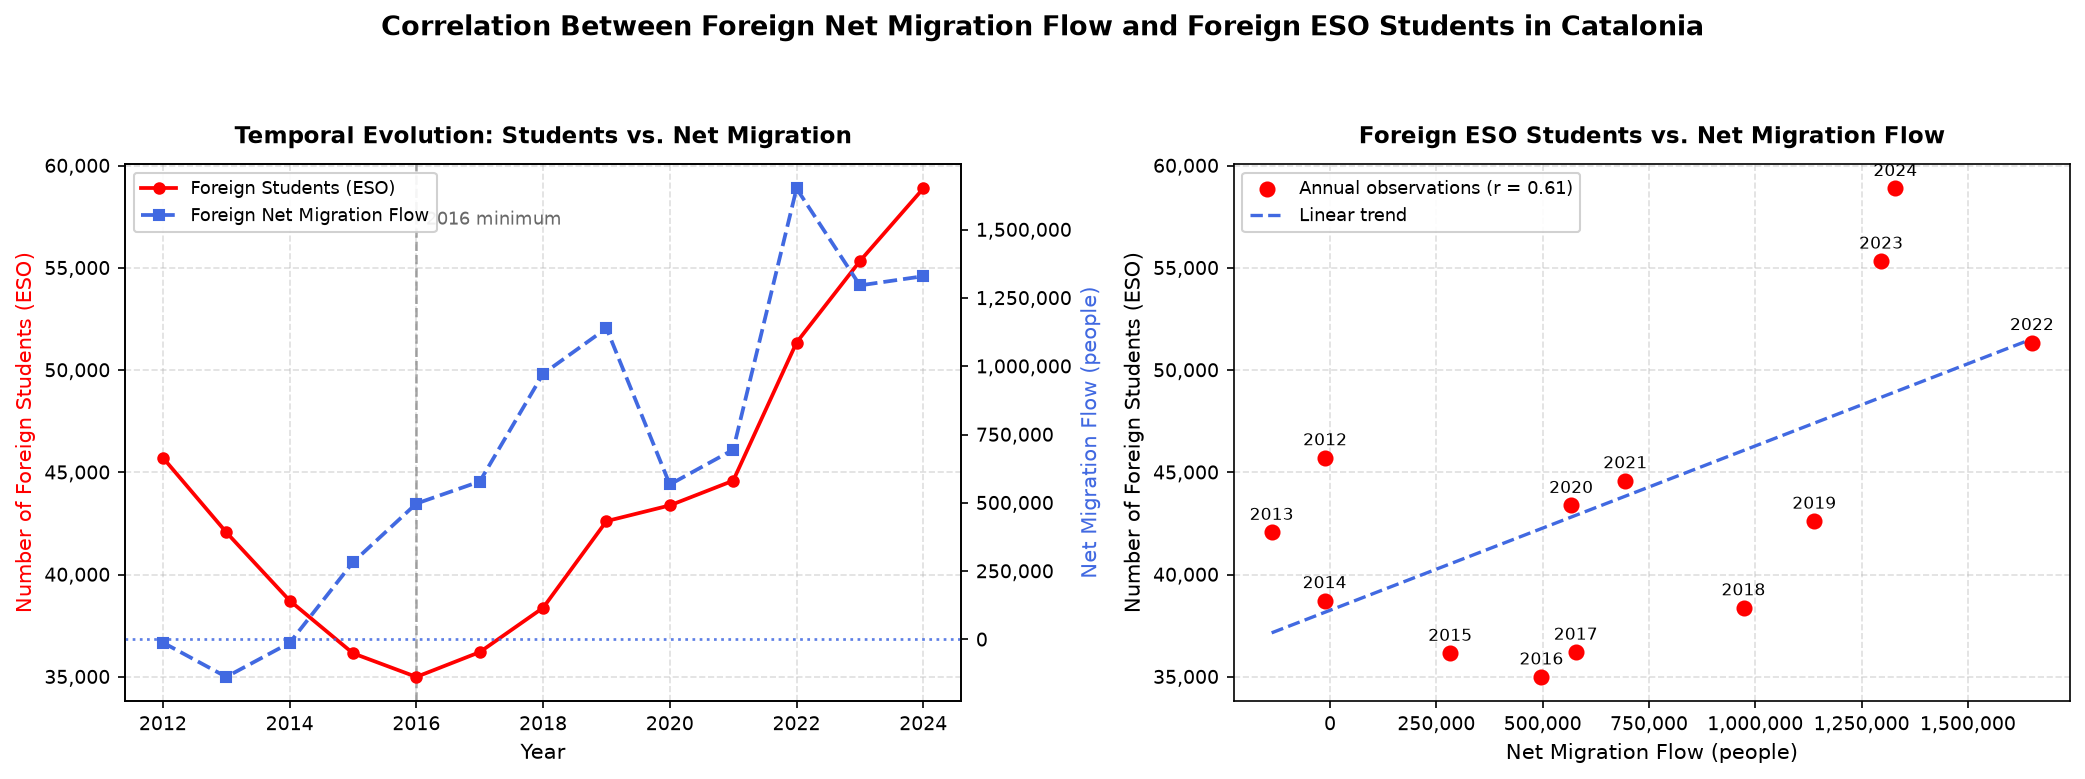

In [5]:
import numpy as np

# 1. Lectura de les dades d'alumnes estrangers a l'ESO (gestionant el punt de milers)
ruta_eso = ROOT_DIR / "data" / "processed" / "education" / "dades_netes_estrangers_eso.csv"
df_eso = pd.read_csv(
    ruta_eso,
    sep=None,
    engine="python",
    thousands=".",
    encoding="utf-8",
    encoding_errors="replace"
)

df_eso_net = pd.DataFrame({
    "Year": pd.to_numeric(df_eso.iloc[:, 0], errors="coerce"),
    "Foreign_Students": pd.to_numeric(
        df_eso.iloc[:, 1]
        .astype(str)
        .str.strip()
        .str.replace(".", "", regex=False)
        .str.replace(",", "", regex=False),
        errors="coerce"
    )
}).dropna()
df_eso_net["Year"] = df_eso_net["Year"].astype(int)

# 2. Fusió dels dos datasets pels anys coincidents i càlcul de correlació
df_comp = pd.merge(df_eso_net, df_flux, on="Year", how="inner").sort_values("Year")

r_pearson = df_comp["Net_Migration"].corr(df_comp["Foreign_Students"])
r_lag1 = df_comp["Net_Migration"].shift(1).corr(df_comp["Foreign_Students"])

print(f"Pearson correlation (same year, r): {r_pearson:.3f}")
print(f"Pearson correlation (1-year lag, r): {r_lag1:.3f}")

# 3. Figura comparativa (2 panells: evolució dual-axis + correlació directa)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=150)

# --- Panell esquerre: Evolució temporal comparada (2016 inflection point) ---
ax1_right = ax1.twinx()

ax1.axvline(2016, color="gray", linestyle="--", linewidth=1.2, alpha=0.7)
ax1.text(2016.15, df_comp["Foreign_Students"].max() * 0.97, "2016 minimum", color="dimgray", fontsize=8.5)

l1 = ax1.plot(
    df_comp["Year"],
    df_comp["Foreign_Students"],
    color="red",
    marker="o",
    markersize=5,
    linewidth=1.8,
    label="Foreign Students (ESO)"
)
l2 = ax1_right.plot(
    df_comp["Year"],
    df_comp["Net_Migration"],
    color="royalblue",
    marker="s",
    markersize=5,
    linewidth=1.8,
    linestyle="--",
    label="Foreign Net Migration Flow"
)

ax1.set_title("Temporal Evolution: Students vs. Net Migration", fontsize=11, fontweight="bold", pad=10)
ax1.set_xlabel("Year", fontsize=10)
ax1.set_ylabel("Number of Foreign Students (ESO)", fontsize=10, color="red")
ax1_right.set_ylabel("Net Migration Flow (people)", fontsize=10, color="royalblue")

ax1.grid(True, linestyle="--", alpha=0.4)
ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax1.tick_params(axis="both", labelsize=9)
ax1_right.tick_params(axis="y", labelsize=9)
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax1_right.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax1_right.axhline(0, color="royalblue", linestyle=":", linewidth=1.3, alpha=0.85, label="Zero migration balance")

linies = l1 + l2
etiquetes = [l.get_label() for l in linies]
ax1.legend(linies, etiquetes, loc="upper left", frameon=True, facecolor="white", framealpha=0.9, fontsize=8.5)

# --- Panell dret: Dispersió Foreign Students vs. Net Migration ---
ax2.scatter(
    df_comp["Net_Migration"],
    df_comp["Foreign_Students"],
    color="red",
    s=45,
    zorder=3,
    label=f"Annual observations (r = {r_pearson:.2f})"
)

# Recta de regressió lineal
m, b = np.polyfit(df_comp["Net_Migration"], df_comp["Foreign_Students"], 1)
x_vals = np.linspace(df_comp["Net_Migration"].min(), df_comp["Net_Migration"].max(), 100)
ax2.plot(x_vals, m * x_vals + b, color="royalblue", linestyle="--", linewidth=1.6, label="Linear trend")

# Etiquetem cada punt amb l'any corresponent
for _, fila in df_comp.iterrows():
    ax2.annotate(
        str(int(fila["Year"])),
        (fila["Net_Migration"], fila["Foreign_Students"]),
        textcoords="offset points",
        xytext=(0, 6),
        ha="center",
        fontsize=8,
        color="black"
    )

ax2.set_title("Foreign ESO Students vs. Net Migration Flow", fontsize=11, fontweight="bold", pad=10)
ax2.set_xlabel("Net Migration Flow (people)", fontsize=10)
ax2.set_ylabel("Number of Foreign Students (ESO)", fontsize=10)

ax2.grid(True, linestyle="--", alpha=0.4)
ax2.tick_params(axis="both", labelsize=9)
ax2.xaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax2.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9, fontsize=8.5)

fig.suptitle(
    "Correlation Between Foreign Net Migration Flow and Foreign ESO Students in Catalonia",
    fontsize=13,
    fontweight="bold",
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.94])

ruta_fig2 = ROOT_DIR / "results" / "figures" / "foreign_students_vs_net_migration.png"
ruta_fig2.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(ruta_fig2, dpi=300, bbox_inches="tight")

plt.show()

 Year  Foreign_Students  Delta_Students  Net_Migration
 2013             42064         -3648.0        -137360
 2014             38724         -3340.0         -12710
 2015             36147         -2577.0         282530
 2016             34992         -1155.0         497190
 2017             36204          1212.0         577870
 2018             38373          2169.0         972290
 2019             42611          4238.0        1138810
 2020             43380           769.0         567020
 2021             44589          1209.0         694220
 2022             51347          6758.0        1650690
 2023             55330          3983.0        1295910
 2024             58881          3551.0        1329430

Pearson correlation (same year, r): 0.976
Pearson correlation (1-year lag, r): 0.763


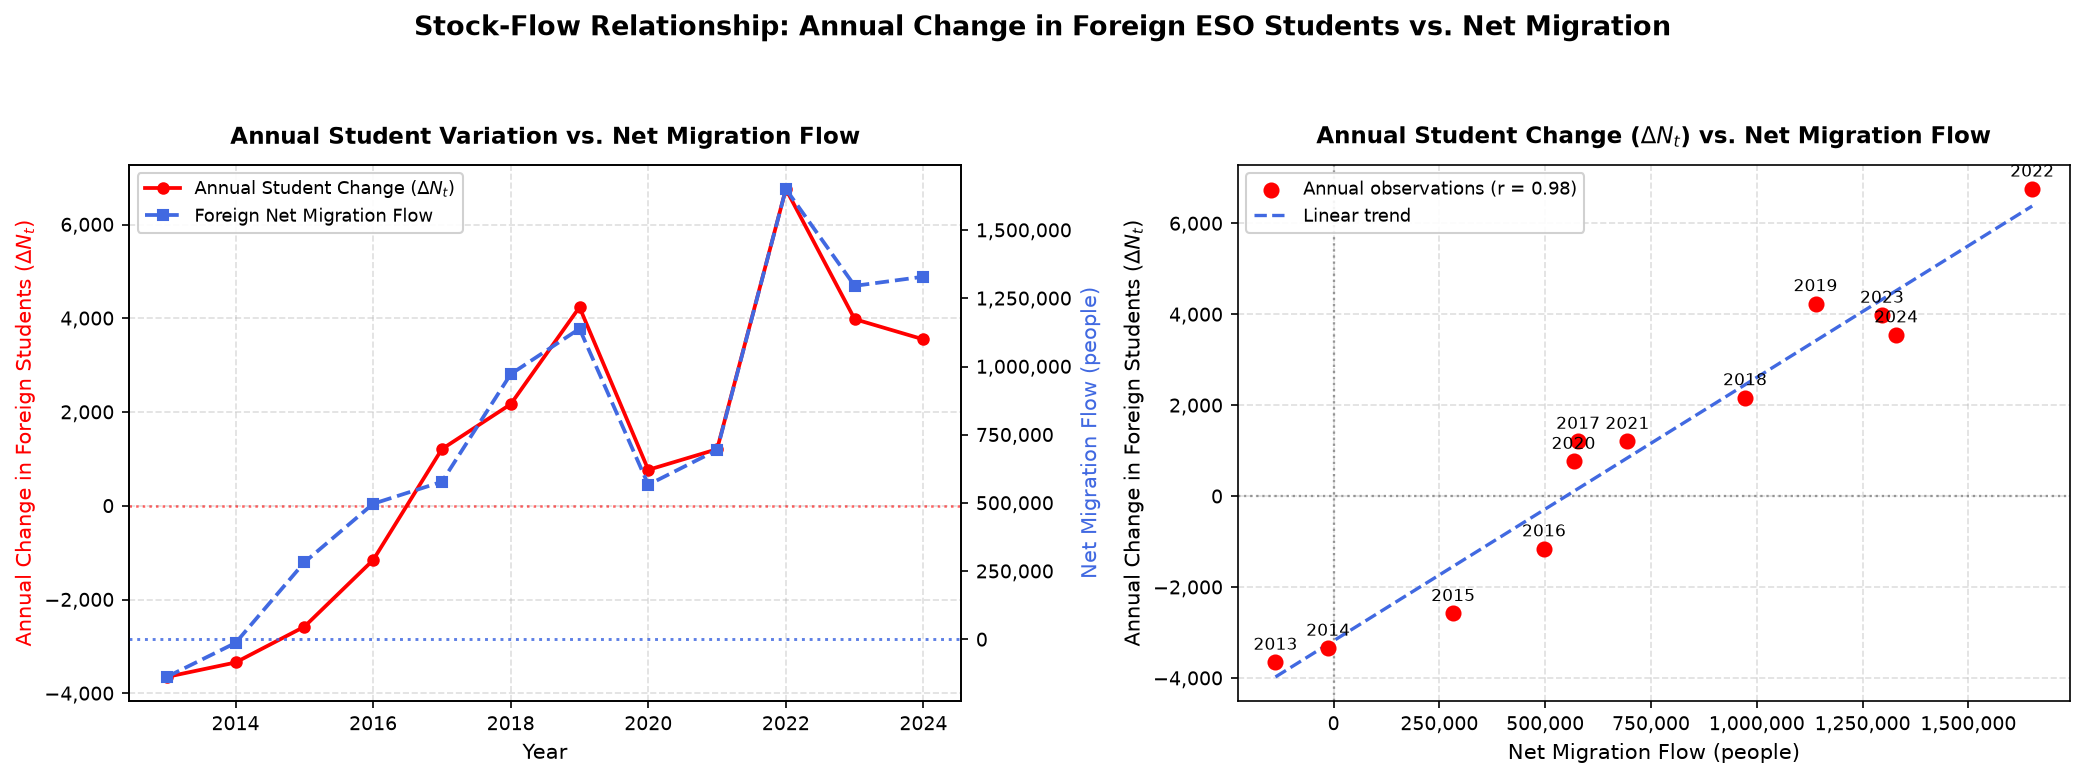

In [6]:
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd

# Recuperem ROOT_DIR si no està definit a la sessió
if "ROOT_DIR" not in globals():
    cwd = Path.cwd().resolve()
    ROOT_DIR = (
        cwd.parents[1]
        if (cwd.parents[1] / "data").exists()
        else (cwd.parents[0] if (cwd.parents[0] / "data").exists() else cwd)
    )

# 1. Calculem la variació anual d'alumnes: Delta_Students_t = Students_t - Students_{t-1}
df_delta = df_comp.sort_values("Year").copy()
df_delta["Delta_Students"] = df_delta["Foreign_Students"].diff()

# Eliminem el primer any (2012), que no té any anterior per calcular el diferencial
df_delta = df_delta.dropna(subset=["Delta_Students"]).copy()

r_delta = df_delta["Net_Migration"].corr(df_delta["Delta_Students"])
r_delta_lag1 = df_comp["Net_Migration"].shift(1).loc[df_delta.index].corr(df_delta["Delta_Students"])

print(df_delta[["Year", "Foreign_Students", "Delta_Students", "Net_Migration"]].to_string(index=False))
print(f"\nPearson correlation (same year, r): {r_delta:.3f}")
print(f"Pearson correlation (1-year lag, r): {r_delta_lag1:.3f}")

# 2. Figura amb 2 panells
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=150)

# --- Panell esquerre: Evolució temporal amb referència y = 0 ---
ax1_right = ax1.twinx()

# Recta horitzontal a y = 0 per a l'eix del flux migratori (i alineació visual del zero)
ax1.axhline(0, color="red", linestyle=":", linewidth=1.2, alpha=0.6)
ax1_right.axhline(0, color="royalblue", linestyle=":", linewidth=1.4, alpha=0.85, label="Zero line (y = 0)")

l1 = ax1.plot(
    df_delta["Year"],
    df_delta["Delta_Students"],
    color="red",
    marker="o",
    markersize=5,
    linewidth=1.8,
    label=r"Annual Student Change ($\Delta N_t$)"
)
l2 = ax1_right.plot(
    df_delta["Year"],
    df_delta["Net_Migration"],
    color="royalblue",
    marker="s",
    markersize=5,
    linewidth=1.8,
    linestyle="--",
    label="Foreign Net Migration Flow"
)

ax1.set_title("Annual Student Variation vs. Net Migration Flow", fontsize=11, fontweight="bold", pad=10)
ax1.set_xlabel("Year", fontsize=10)
ax1.set_ylabel(r"Annual Change in Foreign Students ($\Delta N_t$)", fontsize=10, color="red")
ax1_right.set_ylabel("Net Migration Flow (people)", fontsize=10, color="royalblue")

ax1.grid(True, linestyle="--", alpha=0.4)
ax1.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax1.tick_params(axis="both", labelsize=9)
ax1_right.tick_params(axis="y", labelsize=9)
ax1.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax1_right.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))

linies = l1 + l2
etiquetes = [l.get_label() for l in linies]
ax1.legend(linies, etiquetes, loc="upper left", frameon=True, facecolor="white", framealpha=0.9, fontsize=8.5)

# --- Panell dret: Dispersió Delta_Students vs. Net Migration Flow ---
ax2.axhline(0, color="gray", linestyle=":", linewidth=1.1, alpha=0.8)
ax2.axvline(0, color="gray", linestyle=":", linewidth=1.1, alpha=0.8)

ax2.scatter(
    df_delta["Net_Migration"],
    df_delta["Delta_Students"],
    color="red",
    s=45,
    zorder=3,
    label=f"Annual observations (r = {r_delta:.2f})"
)

# Recta de tendència lineal
m, b = np.polyfit(df_delta["Net_Migration"], df_delta["Delta_Students"], 1)
x_vals = np.linspace(df_delta["Net_Migration"].min(), df_delta["Net_Migration"].max(), 100)
ax2.plot(x_vals, m * x_vals + b, color="royalblue", linestyle="--", linewidth=1.6, label="Linear trend")

for _, fila in df_delta.iterrows():
    ax2.annotate(
        str(int(fila["Year"])),
        (fila["Net_Migration"], fila["Delta_Students"]),
        textcoords="offset points",
        xytext=(0, 6),
        ha="center",
        fontsize=8,
        color="black"
    )

ax2.set_title(r"Annual Student Change ($\Delta N_t$) vs. Net Migration Flow", fontsize=11, fontweight="bold", pad=10)
ax2.set_xlabel("Net Migration Flow (people)", fontsize=10)
ax2.set_ylabel(r"Annual Change in Foreign Students ($\Delta N_t$)", fontsize=10)

ax2.grid(True, linestyle="--", alpha=0.4)
ax2.tick_params(axis="both", labelsize=9)
ax2.xaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax2.yaxis.set_major_formatter(ticker.StrMethodFormatter("{x:,.0f}"))
ax2.legend(loc="upper left", frameon=True, facecolor="white", framealpha=0.9, fontsize=8.5)

fig.suptitle(
    "Stock-Flow Relationship: Annual Change in Foreign ESO Students vs. Net Migration",
    fontsize=13,
    fontweight="bold",
    y=0.99
)

plt.tight_layout(rect=[0, 0, 1, 0.94])

ruta_fig3 = ROOT_DIR / "results" / "figures" / "delta_foreign_students_vs_net_migration.png"
ruta_fig3.parent.mkdir(parents=True, exist_ok=True)
plt.savefig(ruta_fig3, dpi=300, bbox_inches="tight")

plt.show()